In [1]:
import os
import regionmask
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from shapely.geometry import box
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from shapely.errors import GEOSException

In [2]:
def to_month_start_on_time(ds: xr.Dataset) -> xr.Dataset:
    """
    Force ds.time to the first day of each month.
    Works for both ERA5 and GRACE monthly data.
    """
    t = pd.to_datetime(ds.indexes["time"]).to_period("M").to_timestamp()  # month-end by default
    t = t - pd.offsets.MonthEnd(1) + pd.offsets.Day(1)  # shift to first day
    return ds.assign_coords(time=t)

In [3]:
out = "/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed"
era5_path = os.path.join(out, "era5_data.nc")
era5_data = xr.open_dataset(era5_path)
# subset ERA5 from 2002-04-01 onwards (no upper bound yet)
era5_data = era5_data.sel(time=slice("2002-04-01", None))
era5_data = to_month_start_on_time(era5_data)
era5_data

<xarray.Dataset> Size: 5GB
Dimensions:  (time: 273, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2002-04-01 2002-05-01 ... 2024-12-01
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    swe      (time, lat, lon) float32 1GB ...
    t2m      (time, lat, lon) float32 1GB ...
    ppt      (time, lat, lon) float32 1GB ...
    eto      (time, lat, lon) float32 1GB ...

In [4]:
#loading era5 data
era5_land_path = os.path.join("/home/mgurazada/snowdroughts_thirst/data/era5_land_swe", "era5_land_swe_mm_1950_2024_processed.nc")
era5_land_data = xr.open_dataset(era5_land_path)
era5_land_data = era5_land_data.sel(time=slice("2002-04-01", "2024-12-31"))
era5_land_data = to_month_start_on_time(era5_land_data)
era5_land_data

<xarray.Dataset> Size: 4GB
Dimensions:  (time: 273, lat: 901, lon: 3600)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2002-04-01 2002-05-01 ... 2024-12-01
  * lat      (lat) float64 7kB 0.0 0.1 0.2 0.3 0.4 ... 89.6 89.7 89.8 89.9 90.0
  * lon      (lon) float64 29kB -180.0 -179.9 -179.8 ... 179.7 179.8 179.9
Data variables:
    swe      (time, lat, lon) float32 4GB ...

In [5]:
# Compute resolution (in degrees)
dlat = np.abs(era5_data.lat[1] - era5_data.lat[0]).item()
dlon = np.abs(era5_data.lon[1] - era5_data.lon[0]).item()
print(f"ERA5 grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

ERA5 grid spacing: 0.250° lat × 0.250° lon


In [6]:
# Compute resolution (in degrees)
dlat = np.abs(era5_land_data.lat[1] - era5_land_data.lat[0]).item()
dlon = np.abs(era5_land_data.lon[1] - era5_land_data.lon[0]).item()
print(f"ERA5 grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

ERA5 grid spacing: 0.100° lat × 0.100° lon


In [7]:
swsa = xr.open_dataset("/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed/swsa.nc")["sws"]
swsa = swsa.sel(time=~swsa.indexes["time"].duplicated())
swsa

<xarray.DataArray 'sws' (time: 238, lat: 360, lon: 720)> Size: 247MB
[61689600 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 2kB 2002-04-01 2002-05-01 ... 2024-12-01
  * lat      (lat) float64 3kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float64 6kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
    number   int64 8B ...
    expver   (time) <U4 4kB ...

In [8]:
# Compute resolution (in degrees)
dlat = np.abs(swsa.lat[1] - swsa.lat[0]).item()
dlon = np.abs(swsa.lon[1] - swsa.lon[0]).item()
print(f"grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

grid spacing: 0.500° lat × 0.500° lon


In [9]:
def show_time_info(da, name):
    t = pd.to_datetime(da.indexes["time"])
    print(f"{name}: n={len(t)}, min={t.min()}, max={t.max()}, dupes={t.duplicated().sum()}")

show_time_info(era5_data["swe"], "era5-land swe")
show_time_info(era5_data["eto"], "era5 eto")
show_time_info(swsa, "sws")

t = pd.to_datetime(swsa.indexes["time"])
dup_mask  = t.duplicated(keep=False)
dup_times = pd.Series(t[dup_mask]).value_counts().sort_index()
print(dup_times)          # which months are duplicated and how many times

era5-land swe: n=273, min=2002-04-01 00:00:00, max=2024-12-01 00:00:00, dupes=0
era5 eto: n=273, min=2002-04-01 00:00:00, max=2024-12-01 00:00:00, dupes=0
sws: n=238, min=2002-04-01 00:00:00, max=2024-12-01 00:00:00, dupes=0
Series([], Name: count, dtype: int64)


In [10]:
# hydrobasins level 4
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")

bbox_geom = box(-180, 0, 180, 60)
hb = hb[hb.geometry.intersects(bbox_geom)].copy()

hb["geometry"] = hb.geometry.simplify(0.01, preserve_topology=True)
hb["geometry"] = hb.geometry.buffer(0)

print(hb.crs)

EPSG:4326


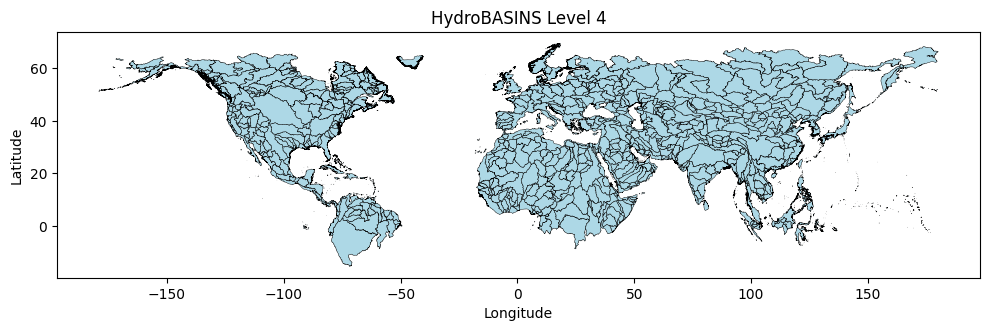

In [11]:
# Plot hydrobasins
fig, ax = plt.subplots(figsize=(10, 6))
hb.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.3)

ax.set_title("HydroBASINS Level 4")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [12]:
main_ids = np.sort(hb["MAIN_BAS"].unique())

geoms   = []
names   = []
abbrevs = []
main_ids_valid = []

for mid in main_ids:
    basin = hb[hb["MAIN_BAS"] == mid]

    try:
        geom = basin.geometry.union_all().buffer(0)

        if geom.is_empty:
            print(f"Skipping MAIN_BAS={mid} (empty after buffer)")
            continue

    except GEOSException as e:
        print(f"Skipping MAIN_BAS={mid} due to topology error: {e}")
        continue

    geoms.append(geom)
    names.append(f"basin_{mid}")
    abbrevs.append(str(mid))
    main_ids_valid.append(mid)

regions = regionmask.Regions(geoms, names=names, abbrevs=abbrevs)

basin_to_region_index = {bid: i for i, bid in enumerate(main_ids_valid)}

print("Number of valid MAIN_BAS regions:", len(main_ids_valid))

Number of valid MAIN_BAS regions: 602


In [13]:
# monthly MODIS snow-cover climatology and turning it into one continuous winter snow-fraction for Dec-Mar.
    
# Load MODIS snow climatology
# Select winter months (Dec–Mar)
# Calculate mean winter snow-cover fraction (Dec–Mar)
# load snow mask climatology (MODIS NSIDC)
snow_path = "/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/snow_mask_monthly_climatology/modis_nsidc_snow_fraction_monthly_0p05deg_v1.nc"
snow = xr.open_dataset(snow_path)

snow_clim = snow["snow_fraction"]

# pick snow months Dec–Mar
snow_winter = snow_clim.sel(month=[12, 1, 2, 3])

# Mean Dec–Mar climatological snow fraction
winter_snow_frac = snow_winter.mean(dim="month")
winter_snow_frac

<xarray.DataArray 'snow_fraction' (lat: 3600, lon: 7200)> Size: 104MB
array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
       [ 1.,  1.,  1., ...,  1.,  1.,  1.],
       [ 1.,  1.,  1., ...,  1.,  1.,  1.],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(3600, 7200), dtype=float32)
Coordinates:
  * lat      (lat) float64 29kB -89.97 -89.92 -89.88 ... 89.88 89.93 89.98
  * lon      (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0

In [14]:
# Load cropland
# Standardize coordinates (x/y → lon/lat)
# Ensure latitude ordering
# Convert cropland to boolean presence

# load cropland (2019)
crop_path = "/home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc"
crop = xr.open_dataset(crop_path)
crop_var_name = list(crop.data_vars)[1]
cropland = crop[crop_var_name]  # e.g., cropland

# If coordinates are named x/y, rename to lon/lat once:
if "x" in cropland.dims and "y" in cropland.dims:
    cropland = cropland.rename({"y": "lat", "x": "lon"})

# sort latitude ascending
if (cropland.lat.diff("lat") < 0).any():
    cropland = cropland.sortby("lat")

print(cropland.min().item(), cropland.max().item())

# Convert cropland percentage (0–100) to fraction (0–1)
cropland_frac = cropland / 100.0

# Safety check
cropland_frac = cropland_frac.clip(0, 1)

cropland_frac.attrs["long_name"] = "Global cropland fraction"
cropland_frac.attrs["units"] = "fraction (0-1)"
cropland_frac.attrs["source"] = "GLAD Global Cropland Extent 2019"

print(
    cropland_frac.min().item(),
    cropland_frac.max().item()
)

0.0 100.0
0.0 1.0


In [15]:
# ============================================================
# ERA5 grid basin mask
# ============================================================

mask3d_era5 = regions.mask_3D(era5_data["lon"], era5_data["lat"], drop=False).load()

# ============================================================
# ERA5 latitude-dependent area weights
# ============================================================

lat_weights_era5 = np.cos(np.deg2rad(era5_data["lat"]))

w2d_era5 = xr.DataArray(lat_weights_era5, coords={"lat": era5_data["lat"]}, dims=["lat"]).broadcast_like(era5_data.isel(time=0, drop=True)).load()

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


In [16]:
# ============================================================
# ERA5-Land grid basin mask
# ============================================================

mask3d_era5_land = regions.mask_3D(era5_land_data["lon"], era5_land_data["lat"], drop=False).load()

# ============================================================
# ERA5-Land latitude-dependent area weights
# ============================================================

lat_weights_era5_land = np.cos(np.deg2rad(era5_land_data["lat"]))

w2d_era5_land = xr.DataArray(lat_weights_era5_land, coords={"lat": era5_land_data["lat"]}, dims=["lat"]).broadcast_like(era5_land_data.isel(time=0, drop=True)).load()

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


In [17]:
# Masks on the two grids
mask_era5 = regions.mask_3D(era5_data["lon"], era5_data["lat"], drop=False, wrap_lon=False)
mask_era5_land = regions.mask_3D(era5_land_data["lon"], era5_land_data["lat"], drop=False, wrap_lon=False)
mask_swsa = regions.mask_3D(swsa["lon"], swsa["lat"], drop=False, wrap_lon=False)

print("n_regions (mask_era5):", mask_era5.sizes["region"])
print("n_regions (mask_era5_land):", mask_era5_land.sizes["region"])
print("n_regions (mask_swsa):", mask_swsa.sizes["region"])

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(
/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


n_regions (mask_era5): 602
n_regions (mask_era5_land): 602
n_regions (mask_swsa): 602


/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


In [18]:
# ============================================================
# Load regridded fractional snow and cropland fields
# ============================================================

snow_on_era5_land = xr.open_dataarray("/home/mgurazada/snowdroughts_thirst/data/regridded/modis_winter_snow_fraction_on_era5_land.nc")
crop_on_era5 = xr.open_dataarray("/home/mgurazada/snowdroughts_thirst/data/regridded/glad_cropland_fraction_on_era5.nc")

# ============================================================
# Basin-level snow and cropland fractions
# ============================================================

basin_weights_snow = mask3d_era5_land * w2d_era5_land
snow_valid_weights = basin_weights_snow.where(snow_on_era5_land.notnull())
basin_snow_frac = (snow_on_era5_land * snow_valid_weights).sum(dim=["lat", "lon"], skipna=True) / snow_valid_weights.sum(dim=["lat", "lon"])
basin_weights_crop = mask3d_era5 * w2d_era5
basin_crop_frac = (crop_on_era5 * basin_weights_crop).sum(dim=["lat", "lon"], skipna=True) / basin_weights_crop.sum(dim=["lat", "lon"], skipna=True)

# ============================================================
# Eligibility threshold
# ============================================================

eligible = basin_snow_frac.notnull() & (basin_snow_frac >= 0.01) & (basin_crop_frac >= 0.01)
eligible_regions = eligible.region.values[eligible.values]
eligible_main_bas = [main_ids_valid[int(r)] for r in eligible_regions]
eligible_set = set(eligible_main_bas)
print("Eligible basins:", len(eligible_main_bas))

Eligible basins: 169


In [19]:
# ============================================================
# Basin-level monthly SWE
# ERA5-Land grid
# ============================================================

SPATIAL_DIM = "z"

swe_s = era5_land_data["swe"].stack({SPATIAL_DIM: ("lat", "lon")})
w_s_snow = w2d_era5_land.stack({SPATIAL_DIM: ("lat", "lon")})
snow_s = snow_on_era5_land.stack({SPATIAL_DIM: ("lat", "lon")})

swe_list = []

for r in eligible_regions:
    basin_mask_s = mask3d_era5_land.sel(region=r).stack({SPATIAL_DIM: ("lat", "lon")})
    valid_cells = basin_mask_s & snow_s.notnull() & (snow_s > 0)
    idx = np.where(valid_cells.values)[0]
    weights_r = w_s_snow.isel(z=idx) * snow_s.isel(z=idx)
    swe_r = swe_s.isel(z=idx)
    valid_weights = weights_r.where(swe_r.notnull())
    basin_mean = (swe_r * valid_weights).sum(dim="z", skipna=True) / valid_weights.sum(dim="z", skipna=True)
    basin_mean = basin_mean.expand_dims(region=[r])
    swe_list.append(basin_mean)

swe_all = xr.concat(swe_list, dim="region")

In [20]:
# ============================================================
# Basin-level monthly ETo
# ERA5 grid
# ============================================================

eto_s = era5_data["eto"].stack({SPATIAL_DIM: ("lat", "lon")})
w_s_crop = w2d_era5.stack({SPATIAL_DIM: ("lat", "lon")})
crop_s = crop_on_era5.stack({SPATIAL_DIM: ("lat", "lon")})

eto_list = []

for r in eligible_regions:
    basin_mask_s = mask3d_era5.sel(region=r).stack({SPATIAL_DIM: ("lat", "lon")})
    valid_cells = basin_mask_s & crop_s.notnull() & (crop_s > 0)
    idx = np.where(valid_cells.values)[0]
    weights_r = w_s_crop.isel(z=idx) * crop_s.isel(z=idx)
    eto_r = eto_s.isel(z=idx)
    valid_weights = weights_r.where(eto_r.notnull())
    basin_mean = (eto_r * valid_weights).sum(dim="z", skipna=True) / valid_weights.sum(dim="z", skipna=True)
    basin_mean = basin_mean.expand_dims(region=[r])
    eto_list.append(basin_mean)

eto_all = xr.concat(eto_list, dim="region")

In [21]:
# ============================================================
# GRACE latitude-dependent area weights
# ============================================================

lat_weights_swsa = np.cos(np.deg2rad(swsa["lat"]))
w2d_swsa = xr.DataArray(lat_weights_swsa, coords={"lat": swsa["lat"]}, dims=["lat"]).broadcast_like(swsa.isel(time=0, drop=True)).load()
swsa_s = swsa.stack(z=("lat", "lon"))
w_s_swsa = w2d_swsa.stack(z=("lat", "lon"))

swe_by_basin = {}
eto_by_basin = {}

for r in eligible_regions:
    main_id = main_ids_valid[int(r)]
    swe_by_basin[main_id] = swe_all.sel(region=r)
    eto_by_basin[main_id] = eto_all.sel(region=r)
    
swsa_by_basin = {}

for r in eligible_regions:
    main_id = main_ids_valid[int(r)]

    basin_mask_s = mask_swsa.sel(region=r).stack(z=("lat", "lon"))
    idx = np.where(basin_mask_s.values)[0]

    if len(idx) == 0:
        swsa_by_basin[main_id] = None
        continue
        
    weights_r = w_s_swsa.isel(z=idx)
    swsa_r = swsa_s.isel(z=idx)
    valid_weights = weights_r.where(swsa_r.notnull())

    basin_mean = (swsa_r * valid_weights).sum(dim="z", skipna=True) / valid_weights.sum(dim="z", skipna=True)

    swsa_by_basin[main_id] = basin_mean

print("Basins with SWE:", len(swe_by_basin))
print("Basins with ETo:", len(eto_by_basin))
print("Basins with SWS:", sum(v is not None for v in swsa_by_basin.values()))

Basins with SWE: 169
Basins with ETo: 169
Basins with SWS: 167


In [22]:
print("Basins with SWE:", sum(v is not None for v in swe_by_basin.values()))
print("Basins with ETo:", sum(v is not None for v in eto_by_basin.values()))
print("Basins with TWS:", sum(v is not None for v in swsa_by_basin.values()))

Basins with SWE: 169
Basins with ETo: 169
Basins with TWS: 167


n basins: 602
MAIN_BAS: 1040028970
SWE is None? False
ETo is None? False
SWSA is None? False
SWSA first 12 values: [ 28.07656511  10.48522852  -8.6234006  -10.84650491 -11.21367142
   6.49217088  37.54821597  30.31601038  18.69779459  16.38411424
  16.46154122   5.21964619]
SWSA time range: 2002-04-01 to 2024-12-01


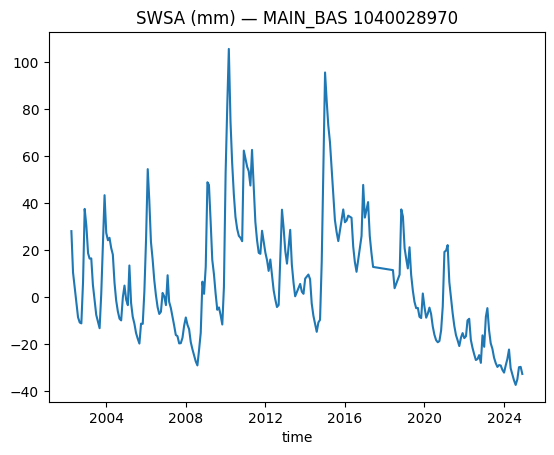

In [23]:
print("n basins:", len(main_ids_valid))

# pick the first basin with a valid TWS series (so plot won't fail)
bid = next(b for b in main_ids_valid if swsa_by_basin.get(b) is not None)

swe_ts = swe_by_basin.get(bid)
eto_ts = eto_by_basin.get(bid)
swsa_ts = swsa_by_basin.get(bid)

print("MAIN_BAS:", bid)
print("SWE is None?", swe_ts is None)
print("ETo is None?", eto_ts is None)
print("SWSA is None?", swsa_ts is None)

print("SWSA first 12 values:", swsa_ts.values[:12])
print("SWSA time range:", str(swsa_ts.time.min().values)[:10], "to", str(swsa_ts.time.max().values)[:10])

swsa_ts.plot()
plt.title(f"SWSA (mm) — MAIN_BAS {bid}")
plt.show()

In [24]:
def water_year(time):
    """
    Assign water year as Oct–Sep.
    """
    year = time.dt.year
    month = time.dt.month
    return xr.where(month >= 10, year + 1, year)

In [25]:
swe_peak_by_basin = {}
eto_summer_by_basin = {}

for bid in main_ids_valid:
    swe_ts = swe_by_basin.get(bid)
    eto_ts = eto_by_basin.get(bid)

    if (swe_ts is None) or (eto_ts is None):
        continue

    swe_ts = swe_ts.assign_coords(wy=water_year(swe_ts.time))
    eto_ts = eto_ts.assign_coords(wy=water_year(eto_ts.time))

    # peak SWE per WY (Dec–Mar)
    is_winter = swe_ts.time.dt.month.isin([12, 1, 2, 3])
    swe_peak = swe_ts.where(is_winter, drop=True).groupby("wy").max("time")

    # summer mean ETo per WY (Apr–Sep)
    is_summer = eto_ts.time.dt.month.isin([4, 5, 6, 7, 8, 9])
    eto_summer = eto_ts.where(is_summer, drop=True).groupby("wy").mean("time")

    swe_peak_by_basin[bid] = swe_peak
    eto_summer_by_basin[bid] = eto_summer

# quick sanity check on one basin that actually exists in the outputs
test_bid = next(b for b in main_ids_valid if b in swe_peak_by_basin)
print("Test basin:", test_bid)
print("SWE peak WY:", swe_peak_by_basin[test_bid])
print("ETo summer WY:", eto_summer_by_basin[test_bid])

Test basin: 1040028970
SWE peak WY: <xarray.DataArray (wy: 23)> Size: 184B
array([1.18720878, 0.85662785, 2.61049408, 8.27072149, 7.03150277,
       2.36230916, 6.75853916, 2.017502  , 2.39255936, 0.96194483,
       1.14240916, 2.10332085, 5.16733075, 5.68738136, 1.9219159 ,
       8.8623843 , 0.80630163, 1.37998649, 1.65927386, 0.89211653,
       5.50112431, 0.26131805, 0.6066478 ])
Coordinates:
  * wy       (wy) int64 184B 2003 2004 2005 2006 2007 ... 2022 2023 2024 2025
    region   int64 8B 39
ETo summer WY: <xarray.DataArray (wy: 23)> Size: 184B
array([148.26872159, 157.67276123, 152.2332945 , 159.52073532,
       153.00556665, 152.74565068, 160.70500188, 159.34312617,
       157.61368976, 154.88637031, 165.32660083, 158.24221823,
       157.32315768, 155.93181821, 154.96254764, 169.08061626,
       147.49705816, 159.33449383, 160.32994024, 155.46293781,
       160.17312675, 164.5255063 , 156.18915469])
Coordinates:
  * wy       (wy) int64 184B 2002 2003 2004 2005 2006 ... 2021 20

In [26]:
q_lo, q_hi = 0.30, 0.70
class_by_basin = {}

for bid in main_ids_valid:
    swe_peak = swe_peak_by_basin.get(bid)
    eto_summer = eto_summer_by_basin.get(bid)

    if (swe_peak is None) or (eto_summer is None):
        continue

    common_wy = np.intersect1d(swe_peak.wy.values, eto_summer.wy.values)
    if len(common_wy) == 0:
        continue

    swe_b = swe_peak.sel(wy=common_wy)
    eto_b = eto_summer.sel(wy=common_wy)

    # drop NaN years (important)
    valid = np.isfinite(swe_b.values) & np.isfinite(eto_b.values)
    swe_b = swe_b.isel(wy=valid)
    eto_b = eto_b.isel(wy=valid)
    if swe_b.sizes["wy"] == 0:
        continue

    common_wy = swe_b.wy.values.astype(int)

    swe_tlow  = float(swe_b.quantile(q_lo, dim="wy"))
    eto_thigh = float(eto_b.quantile(q_hi, dim="wy"))

    low_swe  = swe_b <= swe_tlow
    high_eto = eto_b >= eto_thigh

    df_class = pd.DataFrame({
        "WY": common_wy,
        "low_swe": low_swe.values,
        "high_eto": high_eto.values,
        "normal": (~low_swe & ~high_eto).values,
        "low_swe_only": (low_swe & ~high_eto).values,
        "high_eto_only": (~low_swe & high_eto).values,
        "low_swe_high_eto": (low_swe & high_eto).values,
    })

    class_by_basin[bid] = df_class

test_bid = next(iter(class_by_basin.keys()))
print("Example basin:", test_bid)
print(class_by_basin[test_bid].head())

Example basin: 1040028970
     WY  low_swe  high_eto  normal  low_swe_only  high_eto_only  \
0  2003     True     False   False          True          False   
1  2004     True     False   False          True          False   
2  2005    False      True   False         False           True   
3  2006    False     False    True         False          False   
4  2007    False     False    True         False          False   

   low_swe_high_eto  
0             False  
1             False  
2             False  
3             False  
4             False  


In [27]:
# print classification summary for a given basin ---

def print_basin_summary(bid):
    df = class_by_basin.get(bid)
    if df is None:
        print(f"No classification for basin {bid}")
        return

    print(f"\n=== Basin {bid} — Year Classification Summary ===\n")
    print(df.head())

    print("\nnormal:",              df.loc[df["normal"], "WY"].values)
    print("low swe:",               df.loc[df["low_swe"], "WY"].values)
    print("high eto:",              df.loc[df["high_eto"], "WY"].values)
    print("low swe only:",          df.loc[df["low_swe_only"], "WY"].values)
    print("high eto only:",         df.loc[df["high_eto_only"], "WY"].values)
    print("low swe AND high eto:",  df.loc[df["low_swe_high_eto"], "WY"].values)

    # optional sanity checks
    print("\nCounts:")
    print(df[["normal", "low_swe_only", "high_eto_only", "low_swe_high_eto"]].sum())

    n = len(df)
    ok = int(
        df["normal"].sum()
        + df["low_swe_only"].sum()
        + df["high_eto_only"].sum()
        + df["low_swe_high_eto"].sum()
    ) == n
    print("Total years:", n)
    print("Partition check:", ok)

# run on one example basin
test_bid = next(iter(class_by_basin.keys()))
print_basin_summary(test_bid)


=== Basin 1040028970 — Year Classification Summary ===

     WY  low_swe  high_eto  normal  low_swe_only  high_eto_only  \
0  2003     True     False   False          True          False   
1  2004     True     False   False          True          False   
2  2005    False      True   False         False           True   
3  2006    False     False    True         False          False   
4  2007    False     False    True         False          False   

   low_swe_high_eto  
0             False  
1             False  
2             False  
3             False  
4             False  

normal: [2006 2007 2009 2010 2011 2014 2015 2016 2018 2021]
low swe: [2003 2004 2012 2013 2019 2022 2024]
high eto: [2005 2008 2012 2017 2020 2022 2023]
low swe only: [2003 2004 2013 2019 2024]
high eto only: [2005 2008 2017 2020 2023]
low swe AND high eto: [2012 2022]

Counts:
normal              10
low_swe_only         5
high_eto_only        5
low_swe_high_eto     2
dtype: int64
Total years: 22
Partiti

In [28]:
# deseasonalize + detrend GRACE TWS for each basin

swsa_ds_by_basin = {}   # deseasonalized only
swsa_dt_by_basin = {}   # deseasonalized + detrended

for bid in main_ids_valid:
    swsa_ts = swsa_by_basin.get(bid)

    # skip basins with no soil water storage coverage
    if swsa_ts is None:
        continue

    # 1) remove mean monthly cycle 
    swsa_monclim = swsa_ts.groupby("time.month").mean("time")
    swsa_ds = swsa_ts.groupby("time.month") - swsa_monclim
    swsa_ds.name = "swsa_deseasonalized"

    # 2) fit linear trend and remove it
    lt = swsa_ds.polyfit(dim="time", deg=1, skipna=True)
    trend = xr.polyval(coord=swsa_ds["time"], coeffs=lt.polyfit_coefficients)

    swsa_dt = swsa_ds - trend
    swsa_dt.name = "swsa_deseasonalized_detrended"

    swsa_ds_by_basin[bid] = swsa_ds
    swsa_dt_by_basin[bid] = swsa_dt

# quick sanity check on one basin
test_bid = next(iter(swsa_dt_by_basin.keys()))
print("Test basin:", test_bid)
print(swsa_ds_by_basin[test_bid].isel(time=slice(0, 5)))
print(swsa_dt_by_basin[test_bid].isel(time=slice(0, 5)))

Test basin: 1040028970
<xarray.DataArray 'swsa_deseasonalized' (time: 5)> Size: 40B
array([11.96269967,  3.25550499, -0.75118556, -1.05914139, -2.65419875])
Coordinates:
  * time     (time) datetime64[ns] 40B 2002-04-01 2002-05-01 ... 2002-10-01
    number   (time) int64 40B 0 0 0 0 0
    expver   (time) <U4 80B '0001' '0001' '0001' '0001' '0001'
    month    (time) int64 40B 4 5 8 9 10
<xarray.DataArray 'swsa_deseasonalized_detrended' (time: 5)> Size: 40B
array([ -0.22931509,  -8.84684284, -12.57855481, -12.79385482,
       -14.29924525])
Coordinates:
  * time     (time) datetime64[ns] 40B 2002-04-01 2002-05-01 ... 2002-10-01
    number   (time) int64 40B 0 0 0 0 0
    expver   (time) <U4 80B '0001' '0001' '0001' '0001' '0001'
    month    (time) int64 40B 4 5 8 9 10


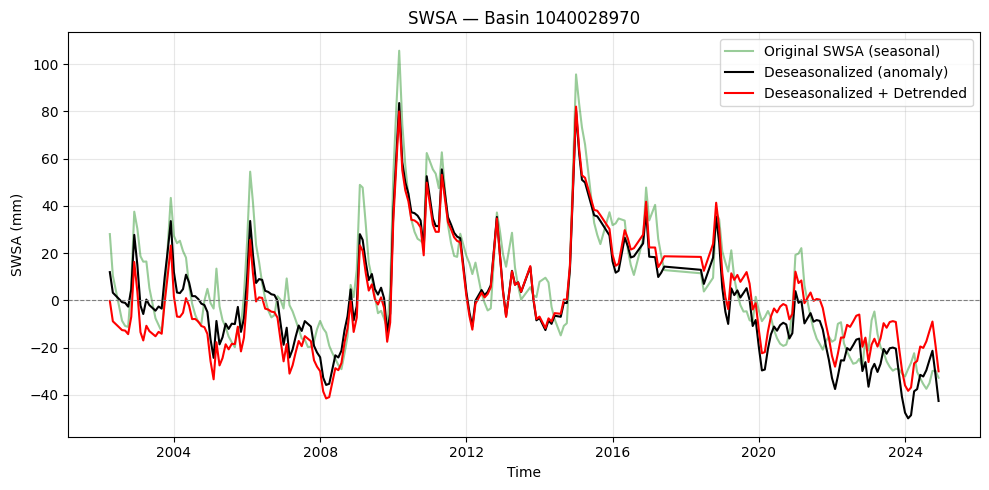

In [29]:
def plot_series_for_basin(bid):
    swsa_ts = swsa_by_basin.get(bid)
    swsa_ds = swsa_ds_by_basin.get(bid)
    swsa_dt = swsa_dt_by_basin.get(bid)

    if (swsa_ts is None) or (swsa_ds is None) or (swsa_dt is None):
        print(f"Missing series for basin {bid}")
        return

    plt.figure(figsize=(10, 5))

    # Original (seasonal)
    plt.plot(
        swsa_ts["time"], swsa_ts,
        label="Original SWSA (seasonal)",
        color="green", alpha=0.4
    )

    # Deseasonalized
    plt.plot(
        swsa_ds["time"], swsa_ds,
        label="Deseasonalized (anomaly)",
        color="black", linewidth=1.5
    )

    # Deseasonalized + detrended
    plt.plot(
        swsa_dt["time"], swsa_dt,
        label="Deseasonalized + Detrended",
        color="red", linewidth=1.5
    )

    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    plt.xlabel("Time")
    plt.ylabel("SWSA (mm)")
    plt.title(f"SWSA — Basin {bid}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# try on one basin
test_bid = next(iter(swsa_ds_by_basin.keys()))
plot_series_for_basin(test_bid)

In [30]:
# interpolate small gaps (≤ 2 months) in GRACE for each basin ---

def interp_small_gaps(da, max_gap=2):
    vals = da.values.copy()
    interp_vals = da.interpolate_na(dim="time", method="linear").values

    isnan = ~np.isfinite(vals)
    i = 0

    while i < len(vals):
        if not isnan[i]:
            i += 1
            continue

        start = i

        while i < len(vals) and isnan[i]:
            i += 1

        end = i
        gap_len = end - start

        if gap_len <= max_gap and start > 0 and end < len(vals):
            vals[start:end] = interp_vals[start:end]

    return xr.DataArray(vals, coords=da.coords, dims=da.dims, attrs=da.attrs, name=da.name)

swsa_ds_interp_by_basin = {}
swsa_dt_interp_by_basin = {}

for bid in main_ids_valid:
    swsa_ds = swsa_ds_by_basin.get(bid)
    swsa_dt = swsa_dt_by_basin.get(bid)
    if (swsa_ds is None) or (swsa_dt is None):
        continue

    swsa_ds_interp = interp_small_gaps(swsa_ds, max_gap=2)
    swsa_dt_interp = interp_small_gaps(swsa_dt, max_gap=2)

    swsa_ds_interp_by_basin[bid] = swsa_ds_interp
    swsa_dt_interp_by_basin[bid] = swsa_dt_interp

# quick check on one basin
test_bid = next(iter(swsa_ds_interp_by_basin.keys()))
print("Check interpolated deseasonalized series for basin:", test_bid)
print(swsa_ds_interp_by_basin[test_bid].isel(time=slice(0, 10)))

Check interpolated deseasonalized series for basin: 1040028970
<xarray.DataArray 'swsa_deseasonalized' (time: 10)> Size: 80B
array([11.96269967,  3.25550499, -0.75118556, -1.05914139, -2.65419875,
        4.59214372, 27.72970241, 14.95825311, -2.17089959, -5.77102891])
Coordinates:
  * time     (time) datetime64[ns] 80B 2002-04-01 2002-05-01 ... 2003-03-01
    number   (time) int64 80B 0 0 0 0 0 0 0 0 0 0
    expver   (time) <U4 160B '0001' '0001' '0001' ... '0001' '0001' '0001'
    month    (time) int64 80B 4 5 8 9 10 11 12 1 2 3


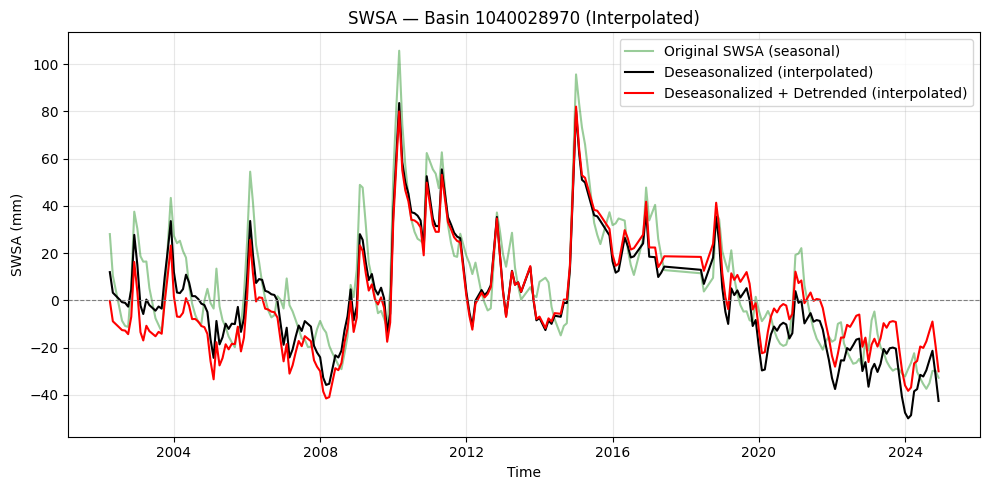

In [31]:
def plot_interpolated_for_basin(bid):
    swsa_ts  = swsa_by_basin.get(bid)
    swsa_ds_i = swsa_ds_interp_by_basin.get(bid)
    swsa_dt_i = swsa_dt_interp_by_basin.get(bid)

    if (swsa_ts is None) or (swsa_ds_i is None) or (swsa_dt_i is None):
        print(f"Missing data for basin {bid}")
        return

    plt.figure(figsize=(10, 5))

    # Original
    plt.plot(
        swsa_ts["time"], swsa_ts,
        label="Original SWSA (seasonal)",
        color="green", alpha=0.4
    )

    # Deseasonalized (interpolated)
    plt.plot(
        swsa_ds_i["time"], swsa_ds_i,
        label="Deseasonalized (interpolated)",
        color="black", linewidth=1.5
    )

    # Deseasonalized + detrended (interpolated)
    plt.plot(
        swsa_dt_i["time"], swsa_dt_i,
        label="Deseasonalized + Detrended (interpolated)",
        color="red", linewidth=1.5
    )

    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    plt.xlabel("Time")
    plt.ylabel("SWSA (mm)")
    plt.title(f"SWSA — Basin {bid} (Interpolated)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# try it on a basin
test_bid = next(iter(swsa_dt_interp_by_basin.keys()))
plot_interpolated_for_basin(test_bid)

In [32]:
# # add water year + find valid GRACE WYs per basin

# rsa_dt_interp_wy_by_basin = {}
# valid_wy_by_basin = {}

# for bid in main_ids_valid:
#     rsa_dt_i = rsa_dt_interp_by_basin.get(bid)
#     if rsa_dt_i is None:
#         continue

#     # add water-year coord (Oct–Sep)
#     rsa_dt_i = rsa_dt_i.assign_coords(wy=water_year(rsa_dt_i.time))

#     valid_years = []
#     for wy in np.unique(rsa_dt_i.wy.values.astype(int)):
#         start = pd.Timestamp(wy - 1, 9, 1)
#         end   = pd.Timestamp(wy,     9, 30)
#         seg   = rsa_dt_i.sel(time=slice(start, end))

#         # require at least 7 months of GRACE in that WY
#         if seg.count() >= 7:
#             valid_years.append(int(wy))

#     rsa_dt_interp_wy_by_basin[bid] = rsa_dt_i
#     valid_wy_by_basin[bid] = valid_years

# # quick sanity check
# test_bid = next(iter(valid_wy_by_basin.keys()))
# print("Basin:", test_bid)
# print("Valid GRACE water years:", valid_wy_by_basin[test_bid])


In [33]:
# add water year + find valid WYs per basin

swsa_ds_interp_wy_by_basin = {}
valid_wy_by_basin = {}

for bid in main_ids_valid:
    swsa_ds_i = swsa_ds_interp_by_basin.get(bid)
    if swsa_ds_i is None:
        continue

    # add water-year coord (Oct–Sep)
    swsa_ds_i = swsa_ds_i.assign_coords(wy=water_year(swsa_ds_i.time))

    valid_years = []
    for wy in np.unique(swsa_ds_i.wy.values.astype(int)):
        start = pd.Timestamp(wy - 1, 9, 1)
        end   = pd.Timestamp(wy,     9, 30)
        seg   = swsa_ds_i.sel(time=slice(start, end))

        # require at least 7 months of GRACE in that WY
        if seg.count() >= 7:
            valid_years.append(int(wy))

    swsa_ds_interp_wy_by_basin[bid] = swsa_ds_i
    valid_wy_by_basin[bid] = valid_years

# quick sanity check
test_bid = next(iter(valid_wy_by_basin.keys()))
print("Basin:", test_bid)
print("Valid water years:", valid_wy_by_basin[test_bid])


Basin: 1040028970
Valid water years: [2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2019, 2020, 2021, 2022, 2023, 2024]


In [34]:
# build year lists per class, per basin (only GRACE-valid WYs)

groups_by_basin = {}

for bid in main_ids_valid:
    df_class = class_by_basin.get(bid)
    valid_wy = valid_wy_by_basin.get(bid)

    if df_class is None or not valid_wy:
        continue

    wy_swsa = set(valid_wy)

    yrs_normal = sorted(set(df_class.loc[df_class["normal"], "WY"].astype(int)) & wy_swsa)
    yrs_low_swe = sorted(set(df_class.loc[df_class["low_swe"], "WY"].astype(int)) & wy_swsa)
    yrs_high_eto = sorted(set(df_class.loc[df_class["high_eto"], "WY"].astype(int)) & wy_swsa)
    yrs_low_swe_only = sorted(set(df_class.loc[df_class["low_swe_only"], "WY"].astype(int)) & wy_swsa)
    yrs_high_eto_only = sorted(set(df_class.loc[df_class["high_eto_only"], "WY"].astype(int)) & wy_swsa)
    yrs_low_swe_high_eto = sorted(set(df_class.loc[df_class["low_swe_high_eto"], "WY"].astype(int)) & wy_swsa)

    groups_by_basin[bid] = {
        "normal": yrs_normal,
        "low_swe": yrs_low_swe,
        "high_eto": yrs_high_eto,
        "low_swe_only": yrs_low_swe_only,
        "high_eto_only": yrs_high_eto_only,
        "low_swe_high_eto": yrs_low_swe_high_eto,
    }

# quick sanity check
test_bid = next(iter(groups_by_basin.keys()))
print("Basin:", test_bid)
for k, v in groups_by_basin[test_bid].items():
    print(k, ":", v)

Basin: 1040028970
normal : [2006, 2007, 2009, 2010, 2011, 2014, 2015, 2016, 2021]
low_swe : [2003, 2004, 2012, 2013, 2019, 2022, 2024]
high_eto : [2005, 2008, 2012, 2017, 2020, 2022, 2023]
low_swe_only : [2003, 2004, 2013, 2019, 2024]
high_eto_only : [2005, 2008, 2017, 2020, 2023]
low_swe_high_eto : [2012, 2022]


In [35]:
# build Sept→Sept SWSA trajectories per basin and class ---

traj_by_basin = {}   # {bid: {group_name: 2D array (n_years, 13)}}
comp_by_basin = {}   # {bid: {group_name: 1D array (13,)}}
delta_by_basin = {}  # {bid: {group_name: float}}

x = np.arange(13)  # 0..12 months from Sept(start)

for bid in groups_by_basin.keys():
    swsa_ds_i = swsa_ds_interp_wy_by_basin.get(bid)
    if swsa_ds_i is None:
        continue

    groups = groups_by_basin[bid]
    traj_by_group = {}
    comp_by_group = {}
    delta_by_group = {}

    for name, years in groups.items():
        curves = []
        kept_years = []

        for wy in years:
            start = pd.Timestamp(wy - 1, 9, 1)
            end   = pd.Timestamp(wy,     9, 30)

            seg = swsa_ds_i.sel(time=slice(start, end)).resample(time="MS").mean()
            ms  = (seg.time.dt.year - start.year) * 12 + (seg.time.dt.month - start.month)

            y = np.full(13, np.nan)
            for m, val in zip(ms.values, seg.values):
                if 0 <= m <= 12:
                    y[int(m)] = val

            # skip this WY if either September endpoint is missing
            if not (np.isfinite(y[0]) and np.isfinite(y[12])):
                continue

            # normalize so Sept(start) = 0
            y = y - y[0]

            curves.append(y)
            kept_years.append(int(wy))

        if curves:
            stack = np.vstack(curves)  # (n_years, 13)
            col_has_data = np.isfinite(stack).any(axis=0)

            comp = np.full(13, np.nan)
            if col_has_data.any():
                comp[col_has_data] = np.nanmean(stack[:, col_has_data], axis=0)

            delta = float(comp[12]) if np.isfinite(comp[12]) else np.nan

            traj_by_group[name]  = stack
            comp_by_group[name]  = comp
            delta_by_group[name] = delta

            # update to only years actually used
            groups[name] = kept_years

    traj_by_basin[bid]  = traj_by_group
    comp_by_basin[bid]  = comp_by_group
    delta_by_basin[bid] = delta_by_group
    groups_by_basin[bid] = groups  # overwrite with kept years

# quick sanity check
test_bid = next(iter(delta_by_basin.keys()))
print("Basin:", test_bid)
print("ΔSWSA (Sep→Sep) [mm] by group:", delta_by_basin[test_bid])

Basin: 1040028970
ΔSWSA (Sep→Sep) [mm] by group: {'normal': 10.956659738583033, 'low_swe': -6.7610136729071915, 'high_eto': -10.227089446677917, 'low_swe_only': -1.2220012512224319, 'high_eto_only': -7.805868017299711, 'low_swe_high_eto': -15.069532305434327}


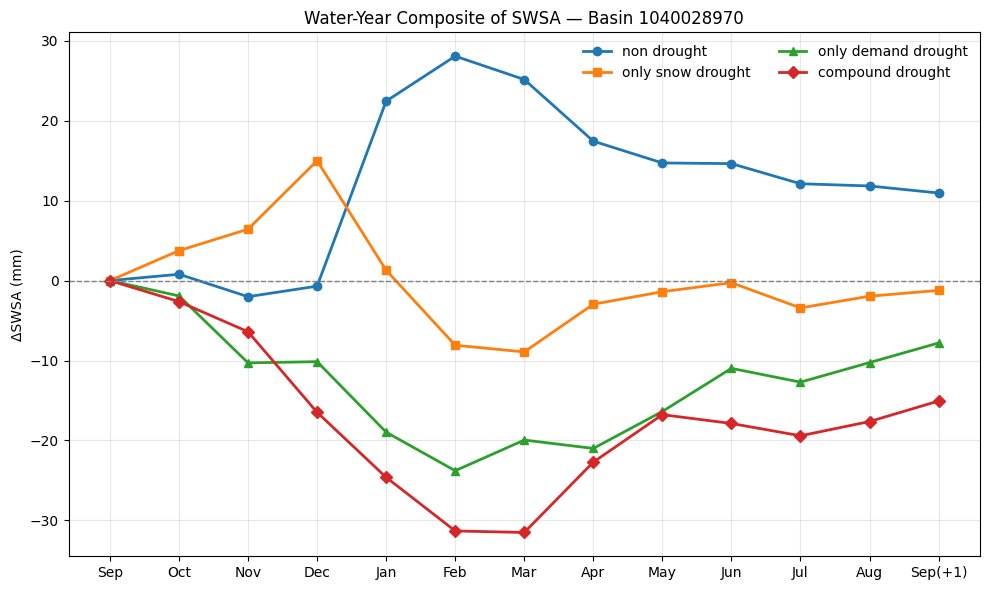

In [36]:
def plot_composite_for_basin(bid):
    """
    Line plot of Sept→Sept SWSA composites for one basin,
    using comp_by_basin[bid] (the per-group 13-month curves).
    """
    if bid not in comp_by_basin:
        print(f"No composites found for basin {bid}")
        return

    comp_by_group = comp_by_basin[bid]

    x = np.arange(13)
    month_labels = [
        "Sep","Oct","Nov","Dec","Jan","Feb","Mar",
        "Apr","May","Jun","Jul","Aug","Sep(+1)"
    ]

    order = [
        "normal",
        "low_swe_only",
        "high_eto_only",
        "low_swe_high_eto",
    ]
    display = {
        "normal": "non drought",
        "low_swe_only": "only snow drought",
        "high_eto_only": "only demand drought",
        "low_swe_high_eto": "compound drought"
    }
    markers = ["o","s","^","D","v","P"]

    fig, ax = plt.subplots(figsize=(10,6))
    line_colors = {}

    for i, name in enumerate(order):
        if name not in comp_by_group:
            continue
        y = comp_by_group[name]
        if y is None:
            continue

        line, = ax.plot(
            x, y,
            marker=markers[i % len(markers)],
            linewidth=2,
            label=display[name]
        )
        line_colors[name] = line.get_color()

    ax.axhline(0, linewidth=1, linestyle="--", color="gray")
    ax.set_xticks(x)
    ax.set_xticklabels(month_labels)
    ax.set_ylabel("ΔSWSA (mm)")
    ax.set_title(f"Water-Year Composite of SWSA — Basin {bid}")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()

# example: pick any basin with composites
test_bid = next(iter(comp_by_basin.keys()))
plot_composite_for_basin(test_bid)


In [37]:
bid = 7030008720

if bid not in comp_by_basin:
    print("No GRACE composites for this basin.")
else:
    plot_composite_for_basin(bid)

No GRACE composites for this basin.


In [38]:
# store results as: results[bid]['comp_vs_normal'] = {...}
ttest_results = {}

for bid, traj_groups in traj_by_basin.items():
    basin_res = {}

    def get_delta(group_name):
        """Return 1D array of ΔSWSA (mm) for each WY in this group."""
        if group_name not in traj_groups:
            return None
        stack = traj_groups[group_name]          # shape (n_years, 13)
        d = stack[:, 12]                         # Sept→Sept change
        d = d[np.isfinite(d)]                    # drop NaNs
        return d

    d_comp   = get_delta("low_swe_high_eto")
    d_norm   = get_delta("normal")
    d_low    = get_delta("low_swe_only")
    d_high   = get_delta("high_eto_only")

    # helper for one comparison
    def add_test(key, a, b):
        if a is None or b is None:
            return
        if (len(a) < 2) or (len(b) < 2):
            return  # too few years for a meaningful t-test
        tstat, pval = ttest_ind(a, b, equal_var=False, nan_policy="omit")
        basin_res[key] = {
            "mean_diff": float(np.nanmean(a) - np.nanmean(b)),  # groupA - groupB
            "p_value": float(pval),
            "n_A": int(len(a)),
            "n_B": int(len(b)),
        }

    # Compound vs non-drought
    add_test("comp_vs_normal", d_comp, d_norm)

    # Compound vs low SWE only
    add_test("comp_vs_low_swe_only", d_comp, d_low)

    # Compound vs high ETo only
    add_test("comp_vs_high_eto_only", d_comp, d_high)

    if basin_res:
        ttest_results[bid] = basin_res

# quick peek at one basin
some_bid = next(iter(ttest_results.keys()))
print("Basin:", some_bid)
print(ttest_results[some_bid])

Basin: 1040028970
{'comp_vs_normal': {'mean_diff': -26.02619204401736, 'p_value': 0.07262165588038123, 'n_A': 2, 'n_B': 7}, 'comp_vs_low_swe_only': {'mean_diff': -13.847531054211895, 'p_value': 0.2746302858220141, 'n_A': 2, 'n_B': 3}, 'comp_vs_high_eto_only': {'mean_diff': -7.263664288134616, 'p_value': 0.48434092703746745, 'n_A': 2, 'n_B': 4}}


In [39]:
# Build ΔTWS differences per basin

delta_comp_norm_by_basin     = {}
delta_comp_lowonly_by_basin  = {}
delta_comp_highonly_by_basin = {}

for bid, dct in delta_by_basin.items():
    d_comp    = dct.get("low_swe_high_eto", np.nan)
    d_normal  = dct.get("normal", np.nan)
    d_lowonly = dct.get("low_swe_only", np.nan)
    d_highonly = dct.get("high_eto_only", np.nan)

    # Compound vs non-drought
    if np.isfinite(d_comp) and np.isfinite(d_normal):
        delta_comp_norm_by_basin[bid] = d_comp - d_normal
    else:
        delta_comp_norm_by_basin[bid] = np.nan

    # Compound vs low SWE only
    if np.isfinite(d_comp) and np.isfinite(d_lowonly):
        delta_comp_lowonly_by_basin[bid] = d_comp - d_lowonly
    else:
        delta_comp_lowonly_by_basin[bid] = np.nan

    # Compound vs high ETo only
    if np.isfinite(d_comp) and np.isfinite(d_highonly):
        delta_comp_highonly_by_basin[bid] = d_comp - d_highonly
    else:
        delta_comp_highonly_by_basin[bid] = np.nan

In [40]:
# One geometry per MAIN_BAS + attach all three fields

basins_diss = hb.dissolve(by="MAIN_BAS").reset_index()

basins_diss["dSWSA_comp_minus_norm"]     = basins_diss["MAIN_BAS"].map(delta_comp_norm_by_basin)
basins_diss["dSWSA_comp_minus_lowonly"]  = basins_diss["MAIN_BAS"].map(delta_comp_lowonly_by_basin)
basins_diss["dSWSA_comp_minus_highonly"] = basins_diss["MAIN_BAS"].map(delta_comp_highonly_by_basin)

In [41]:
p_comp_norm_by_basin     = {}
p_comp_lowonly_by_basin  = {}
p_comp_highonly_by_basin = {}

for bid in basins_diss["MAIN_BAS"].values:
    res = ttest_results.get(bid, {})

    # Compound vs non-drought
    if "comp_vs_normal" in res:
        p_comp_norm_by_basin[bid] = res["comp_vs_normal"]["p_value"]
    else:
        p_comp_norm_by_basin[bid] = np.nan

    # Compound vs low SWE only
    if "comp_vs_low_swe_only" in res:
        p_comp_lowonly_by_basin[bid] = res["comp_vs_low_swe_only"]["p_value"]
    else:
        p_comp_lowonly_by_basin[bid] = np.nan

    # Compound vs high ETo only
    if "comp_vs_high_eto_only" in res:
        p_comp_highonly_by_basin[bid] = res["comp_vs_high_eto_only"]["p_value"]
    else:
        p_comp_highonly_by_basin[bid] = np.nan

In [42]:
def plot_global_delta(column, title, p_dict=None, alpha=0.05):
    valid = basins_diss[basins_diss[column].notna()]
    if valid.empty:
        print(f"No data to plot for {column}")
        return

    # Fixed limits
    vmin, vmax = -120, 120
    bounds = np.arange(vmin, vmax + 20, 20)
    n_bins = len(bounds) - 1

    base_cmap = plt.get_cmap("RdBu", n_bins)
    colors = base_cmap(np.linspace(0, 1, n_bins))

    # make -20..0 and 0..20 white
    colors[5] = [1, 1, 1, 1]
    colors[6] = [1, 1, 1, 1]

    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

    # Create figure/axis in a consistent way
    fig, ax = plt.subplots(
        figsize=(12, 6),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

    ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

    # First reserve layout space
    fig.subplots_adjust(top=0.90, bottom=0.16, left=0.02, right=0.98)

    # Then place identical colorbar axis in figure coordinates
    cax = fig.add_axes([0.15, 0.14, 0.70, 0.03])

    basins_diss.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        norm=norm,
        edgecolor="black",
        linewidth=0.2,
        legend=True,
        cax=cax,
        transform=ccrs.PlateCarree(),
        legend_kwds={
            "orientation": "horizontal",
            "label": "ΔSWSA (mm)",
            "ticks": bounds
        },
        missing_kwds={
            "color": "lightgray",
            "edgecolor": "black",
            "label": "Insufficient data"
        },
    )

    if p_dict is not None:
        sig_ids = [
            bid for bid, p in p_dict.items()
            if (p is not None) and np.isfinite(p) and (p < alpha)
        ]

        print(f"{len(sig_ids)} significant basins (p < {alpha}) for {title}")

        sig_gdf = basins_diss[basins_diss["MAIN_BAS"].isin(sig_ids)]

        if not sig_gdf.empty:
            sig_gdf.plot(
                ax=ax,
                facecolor="none",
                edgecolor="black",
                linewidth=0.4,
                hatch="///",
                transform=ccrs.PlateCarree()
            )

            hatch_patch = mpatches.Patch(
                facecolor="none",
                edgecolor="black",
                hatch="///",
                label="p < 0.05"
            )
            ax.legend(
                handles=[hatch_patch],
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=False
            )

    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.show()

30 significant basins (p < 0.05) for ΔSWSA (Sep→Sep): Compound − Non-drought


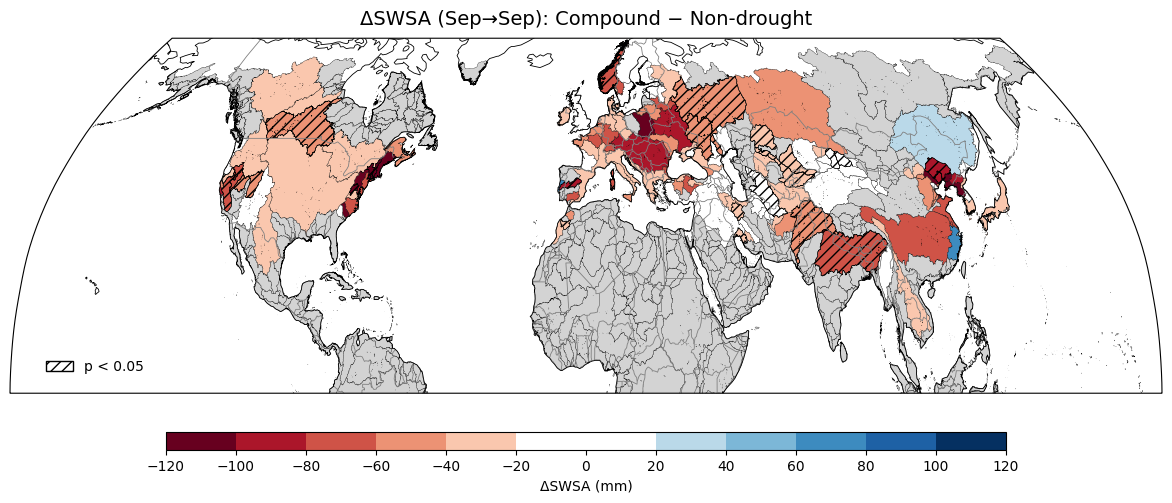

In [43]:
plot_global_delta(
    "dSWSA_comp_minus_norm",
    "ΔSWSA (Sep→Sep): Compound − Non-drought",
    p_dict=p_comp_norm_by_basin,
    alpha=0.05
)

6 significant basins (p < 0.05) for ΔSWSA (Sep→Sep): Compound − snow drought only


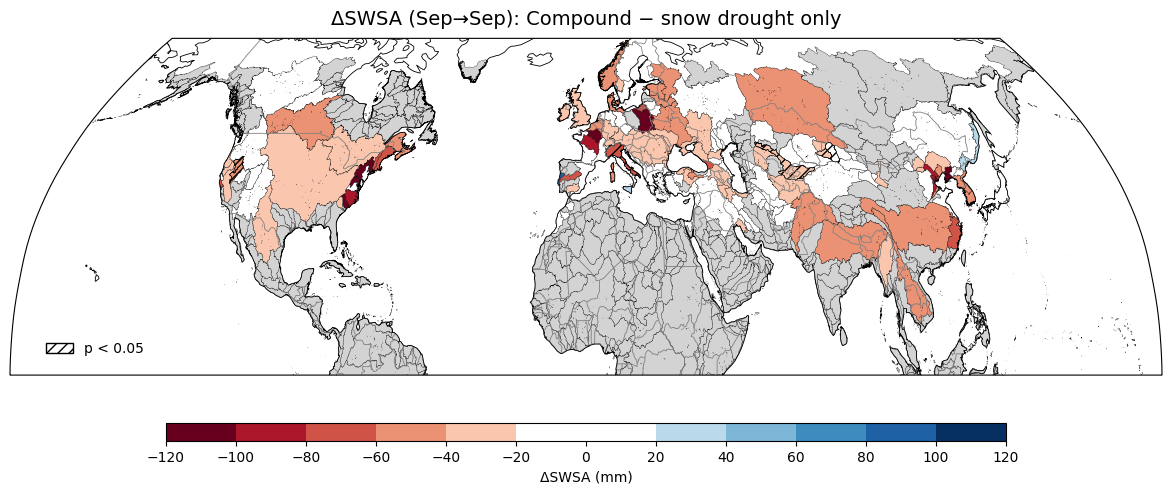

In [44]:
plot_global_delta(
    "dSWSA_comp_minus_lowonly",
    "ΔSWSA (Sep→Sep): Compound − snow drought only",
    p_dict=p_comp_lowonly_by_basin,
    alpha=0.05
)

8 significant basins (p < 0.05) for ΔSWSA (Sep→Sep): Compound − demand drought only


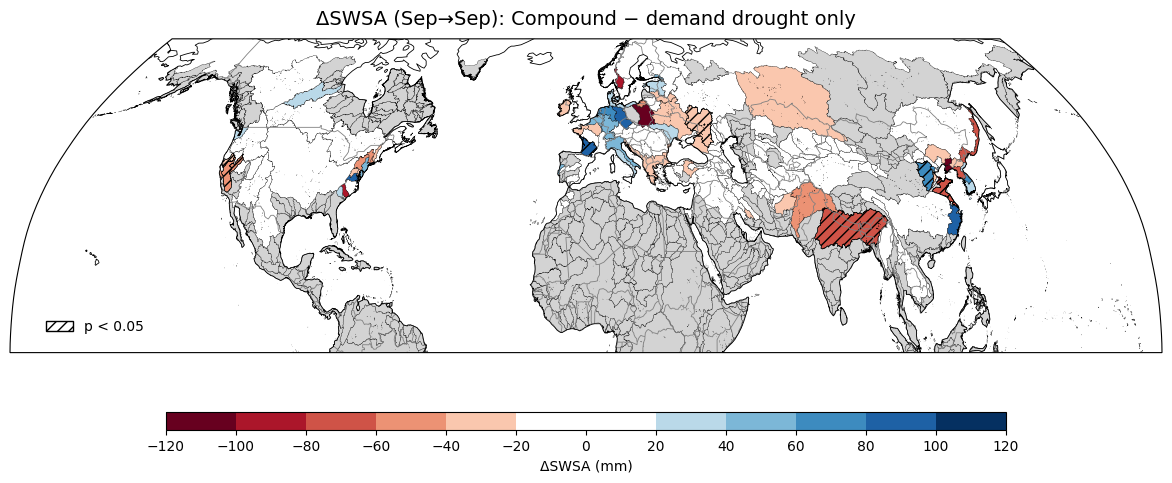

In [45]:
plot_global_delta(
    "dSWSA_comp_minus_highonly",
    "ΔSWSA (Sep→Sep): Compound − demand drought only",
    p_dict=p_comp_highonly_by_basin,
    alpha=0.05
)

(d) ΔSM (Sep→Sep): Cascading − No-drought
{'n_valid': 156, 'n_sig': 30, 'n_inc': 0, 'n_dec': 30, 'pct_inc': 0.0, 'pct_dec': 19.23076923076923}
(e) ΔSM (Sep→Sep): Cascading − Snow-drought-only
{'n_valid': 156, 'n_sig': 6, 'n_inc': 0, 'n_dec': 6, 'pct_inc': 0.0, 'pct_dec': 3.8461538461538463}
(f) ΔSM (Sep→Sep): Cascading − High-evaporative demand-only
{'n_valid': 155, 'n_sig': 8, 'n_inc': 2, 'n_dec': 6, 'pct_inc': 1.2903225806451613, 'pct_dec': 3.870967741935484}
Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_5.png


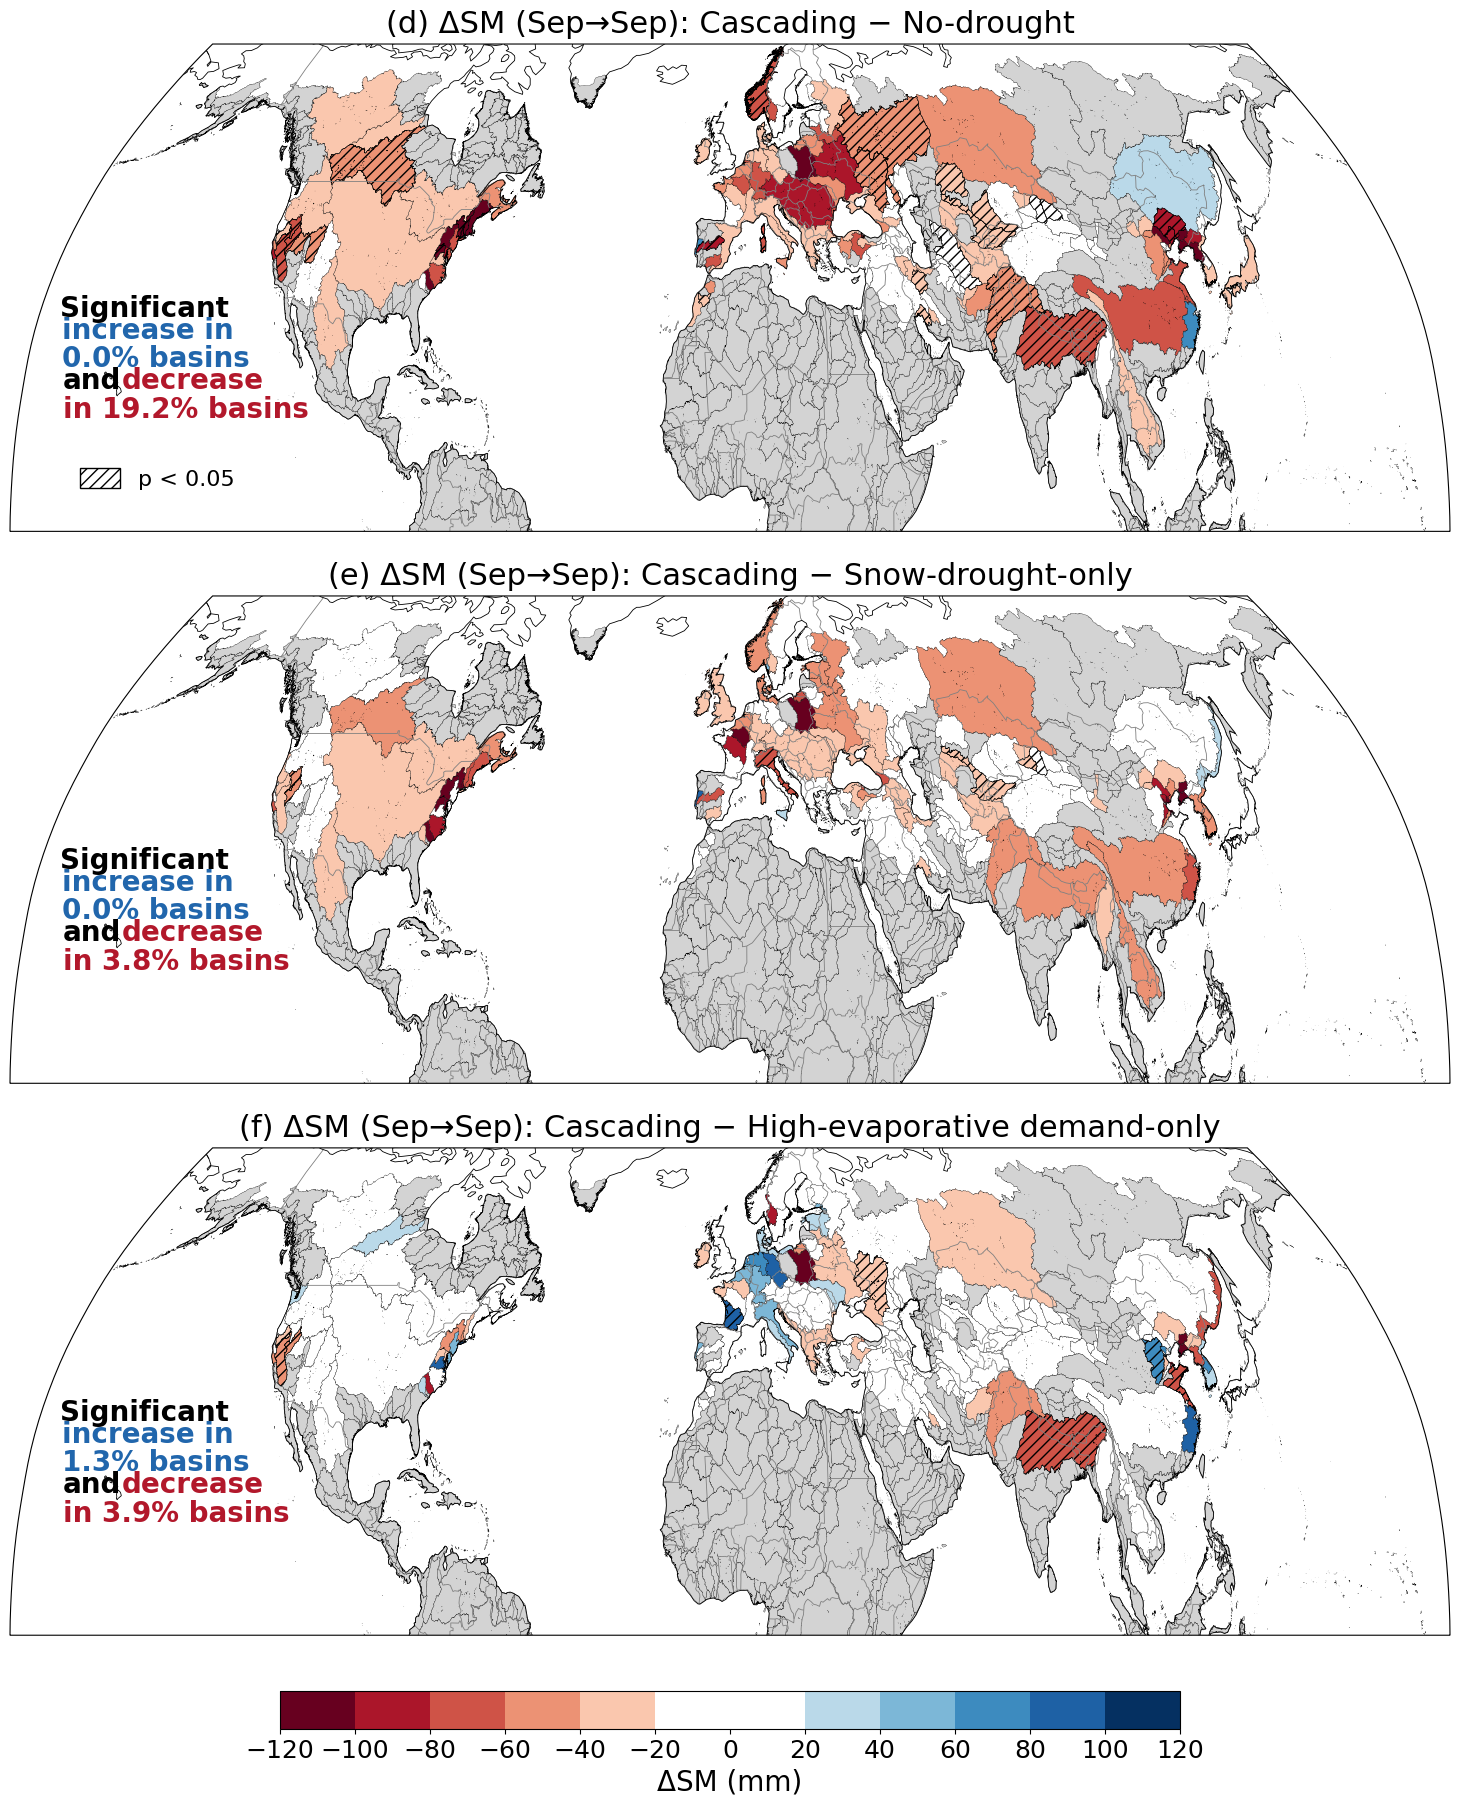

In [46]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


# ------------------------------------------------------------
# Helper: count significant positive / negative basins
# Percentages are relative to basins with non-missing values
# for the plotted column.
# ------------------------------------------------------------
def get_sig_stats(gdf, column, p_dict, alpha=0.05):
    pvals = gdf["MAIN_BAS"].map(p_dict)

    valid = gdf[column].notna()
    sig = valid & pvals.notna() & (pvals < alpha)

    sig_inc = sig & (gdf[column] > 0)
    sig_dec = sig & (gdf[column] < 0)

    n_valid = int(valid.sum())
    n_sig = int(sig.sum())
    n_inc = int(sig_inc.sum())
    n_dec = int(sig_dec.sum())

    pct_inc = 100 * n_inc / n_valid if n_valid > 0 else np.nan
    pct_dec = 100 * n_dec / n_valid if n_valid > 0 else np.nan

    return {
        "n_valid": n_valid,
        "n_sig": n_sig,
        "n_inc": n_inc,
        "n_dec": n_dec,
        "pct_inc": pct_inc,
        "pct_dec": pct_dec,
    }


# ------------------------------------------------------------
# Panel plotting function
# ------------------------------------------------------------
def plot_global_delta_panels_vertical(
    gdf,
    outname="Fig_5.png",
    alpha=0.05
):
    # --------------------------------------------------------
    # Panel definitions
    # --------------------------------------------------------
    panel_info = [
        {
            "column": "dSWSA_comp_minus_norm",
            "title": "(d) ΔSM (Sep→Sep): Cascading − No-drought",
            "p_dict": p_comp_norm_by_basin,
        },
        {
            "column": "dSWSA_comp_minus_lowonly",
            "title": "(e) ΔSM (Sep→Sep): Cascading − Snow-drought-only",
            "p_dict": p_comp_lowonly_by_basin,
        },
        {
            "column": "dSWSA_comp_minus_highonly",
            "title": "(f) ΔSM (Sep→Sep): Cascading − High-evaporative demand-only",
            "p_dict": p_comp_highonly_by_basin,
        },
    ]

    # --------------------------------------------------------
    # Shared color scale
    # --------------------------------------------------------
    vmin, vmax = -120, 120
    bounds = np.arange(vmin, vmax + 20, 20)
    n_bins = len(bounds) - 1

    base_cmap = plt.get_cmap("RdBu", n_bins)
    colors = base_cmap(np.linspace(0, 1, n_bins))

    # Make -20..0 and 0..20 white
    colors[5] = [1, 1, 1, 1]
    colors[6] = [1, 1, 1, 1]

    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        nrows=3,
        ncols=1,
        figsize=(15, 17),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    title_fs = 22
    annotation_fs = 20
    legend_fs = 16
    cbar_label_fs = 20
    cbar_tick_fs = 18

    # --------------------------------------------------------
    # Plot each panel
    # --------------------------------------------------------
    for i, info in enumerate(panel_info):
        ax = axes[i]
        column = info["column"]
        title = info["title"]
        p_dict = info["p_dict"]

        stats = get_sig_stats(gdf, column, p_dict, alpha=alpha)

        print(title)
        print(stats)

        ax.set_global()

        ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

        # Main polygons
        gdf.plot(
            ax=ax,
            column=column,
            cmap=cmap,
            norm=norm,
            edgecolor="black",
            linewidth=0.2,
            legend=False,
            transform=ccrs.PlateCarree(),
            missing_kwds={
                "color": "lightgray",
                "edgecolor": "black",
            },
        )

        # Hatching for significance
        sig_ids = [
            bid for bid, p in p_dict.items()
            if (p is not None) and np.isfinite(p) and (p < alpha)
        ]

        sig_gdf = gdf[gdf["MAIN_BAS"].isin(sig_ids)]

        if not sig_gdf.empty:
            sig_gdf.plot(
                ax=ax,
                facecolor="none",
                edgecolor="black",
                linewidth=0.35,
                hatch="///",
                transform=ccrs.PlateCarree()
            )
            
        ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
        # force all Cartopy panels to use the same visible axis width/height
        ax.set_aspect("auto")
        
        ax.set_title(title, fontsize=title_fs, pad=8)
        ax.set_xticks([])
        ax.set_yticks([])

        # ----------------------------------------------------
        # Annotation block
        # ----------------------------------------------------

        # one compact significance block
        x_text = -172
        
        # Significant
        ax.text(
            x_text-3, 31,
            "Significant",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # increase block
        ax.text(
            x_text, 26,
            f"increase in\n{stats['pct_inc']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#2166ac",
            ha="left",
            va="center",
            fontweight="bold",
            linespacing=1.0
        )
        
        # "and decrease in" on same line
        y_dec = 22
        
        ax.text(
            x_text+2, y_dec-1,
            "and",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        ax.text(
            x_text + 17, y_dec-1,   # shift right so it sits on same line after "and"
            "decrease",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#b2182b",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # second line for decrease %
        ax.text(
            x_text + 3, y_dec-5,
            f"in {stats['pct_dec']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#b2182b",
            ha="left",
            va="center",
            fontweight="bold"
        )

        # Hatch legend only once
        if i == 0:
            hatch_patch = mpatches.Patch(
                facecolor="white",
                edgecolor="black",
                hatch="///",
                label=f"p < {alpha}"
            )

            ax.legend(
                handles=[hatch_patch],
                loc="lower left",
                bbox_to_anchor=(0.035, 0.045),
                frameon=False,
                fontsize=legend_fs,
                handlelength=1.8,
                handleheight=1.0
            )

    # --------------------------------------------------------
    # First apply broad layout
    # --------------------------------------------------------
    plt.subplots_adjust(
        top=0.96,
        bottom=0.10,
        left=0.02,
        right=0.98,
        hspace=0.00
    )

    # --------------------------------------------------------
    # Manually make panel spacing even
    # --------------------------------------------------------
    fig.canvas.draw()

    pos0 = axes[0].get_position()

    panel_x = pos0.x0
    panel_w = pos0.width
    panel_h = pos0.height

    # vertical position of top panel
    y_top = pos0.y0

    # equal gap between panels
    gap = 0.038

    axes[0].set_position([
        panel_x,
        y_top,
        panel_w,
        panel_h
    ])

    axes[1].set_position([
        panel_x,
        y_top - panel_h - gap,
        panel_w,
        panel_h
    ])

    axes[2].set_position([
        panel_x,
        y_top - 2 * panel_h - 2 * gap,
        panel_w,
        panel_h
    ])

    # reset extent after positioning
    for ax in axes:
        ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
        ax.set_aspect("auto")

    # --------------------------------------------------------
    # Common colorbar under bottom panel
    # --------------------------------------------------------
    fig.canvas.draw()
    pos3 = axes[2].get_position()

    cax = fig.add_axes([
        pos3.x0 + 0.18,
        pos3.y0 - 0.055,
        pos3.width - 0.36,
        0.022
    ])

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=bounds,
        spacing="proportional"
    )

    cb.set_label("ΔSM (mm)", fontsize=cbar_label_fs)
    cb.ax.tick_params(labelsize=cbar_tick_fs)

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------
    outpath = os.path.abspath(outname)
    fig.savefig(outpath, dpi=300, bbox_inches="tight", facecolor="white")    
    print(f"Saved figure to: {outpath}")

    plt.show()

plot_global_delta_panels_vertical(
    basins_diss,
    outname="Fig_5.png",
    alpha=0.05
)

Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_5a.png


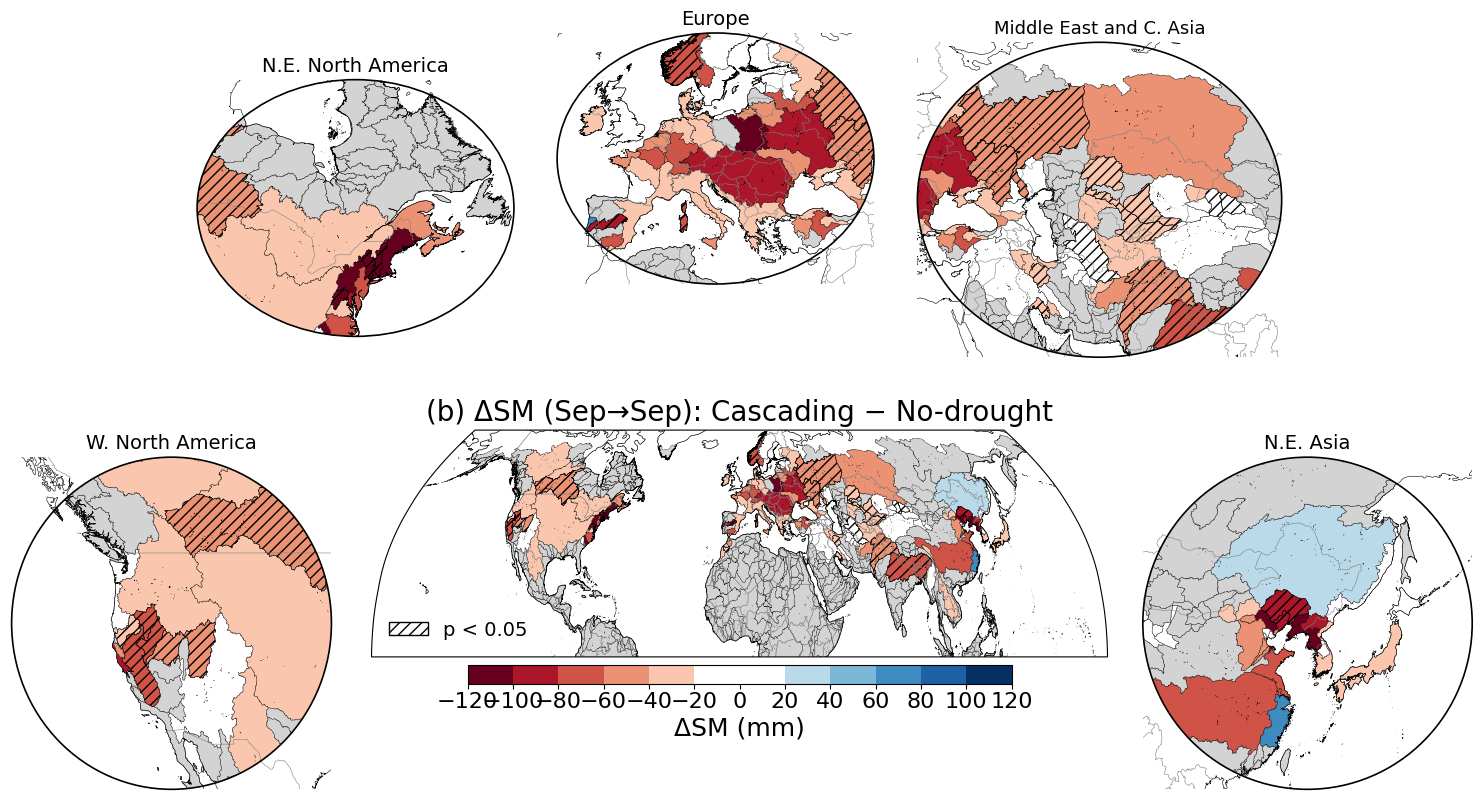

In [47]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

def get_sig_stats(gdf, column, p_dict, alpha=0.05):
    pvals = gdf["MAIN_BAS"].map(p_dict)
    valid = gdf[column].notna()
    sig = valid & pvals.notna() & (pvals < alpha)
    sig_inc = sig & (gdf[column] > 0)
    sig_dec = sig & (gdf[column] < 0)

    n_valid = int(valid.sum())
    n_sig = int(sig.sum())
    n_inc = int(sig_inc.sum())
    n_dec = int(sig_dec.sum())

    pct_inc = 100 * n_inc / n_valid if n_valid > 0 else np.nan
    pct_dec = 100 * n_dec / n_valid if n_valid > 0 else np.nan

    return {
        "n_valid": n_valid,
        "n_sig": n_sig,
        "n_inc": n_inc,
        "n_dec": n_dec,
        "pct_inc": pct_inc,
        "pct_dec": pct_dec
    }

def plot_swsa_panel_with_circles(gdf, column="dSWSA_comp_minus_norm", p_dict=p_comp_norm_by_basin, title="(d) ΔSM (Sep→Sep): Cascading − No-drought", outname="Fig_5d.png", alpha=0.05):
    stats = get_sig_stats(gdf, column, p_dict, alpha=alpha)

    bounds = np.arange(-120, 121, 20)
    n_bins = len(bounds) - 1

    base_cmap = plt.get_cmap("RdBu", n_bins)
    cmap_colors = base_cmap(np.linspace(0, 1, n_bins))

    cmap_colors[5] = [1, 1, 1, 1]
    cmap_colors[6] = [1, 1, 1, 1]

    cmap = mcolors.ListedColormap(cmap_colors)
    norm = mcolors.BoundaryNorm(bounds, ncolors=cmap.N, clip=True)

    sig_ids = [bid for bid, p in p_dict.items() if (p is not None) and np.isfinite(p) and (p < alpha)]
    sig_gdf = gdf[gdf["MAIN_BAS"].isin(sig_ids) & gdf[column].notna()]

    fig = plt.figure(figsize=(16, 11))

    # ============================================================
    # Main map
    # ============================================================

    ax = fig.add_axes([0.27, 0.30, 0.46, 0.30], projection=ccrs.Robinson())

    ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="gray")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    gdf.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        norm=norm,
        edgecolor="black",
        linewidth=0.2,
        legend=False,
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "edgecolor": "black"}
    )

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            linewidth=0.3,
            hatch="///",
            transform=ccrs.PlateCarree()
        )

    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=20, pad=7)
    ax.set_xticks([])
    ax.set_yticks([])

    # ============================================================
    # Significance annotation
    # ============================================================

    # x_text = -172

    # ax.text(x_text - 3, 31, "Significant", transform=ccrs.PlateCarree(), fontsize=16, color="black", ha="left", va="center", fontweight="bold")
    # ax.text(x_text, 26, f"increase in\n{stats['pct_inc']:.1f}% basins", transform=ccrs.PlateCarree(), fontsize=16, color="#2166ac", ha="left", va="center", fontweight="bold", linespacing=1.0)

    # y_dec = 22

    # ax.text(x_text + 2, y_dec - 1, "and", transform=ccrs.PlateCarree(), fontsize=16, color="black", ha="left", va="center", fontweight="bold")
    # ax.text(x_text + 17, y_dec - 1, "decrease", transform=ccrs.PlateCarree(), fontsize=16, color="#b2182b", ha="left", va="center", fontweight="bold")
    # ax.text(x_text + 3, y_dec - 5, f"in {stats['pct_dec']:.1f}% basins", transform=ccrs.PlateCarree(), fontsize=16, color="#b2182b", ha="left", va="center", fontweight="bold")

    # ============================================================
    # Significance legend
    # ============================================================

    hatch_patch = mpatches.Patch(facecolor="white", edgecolor="black", hatch="///", label=f"p < {alpha}")

    ax.legend(handles=[hatch_patch], loc="lower left", frameon=False, fontsize=14)

    # ============================================================
    # Colorbar
    # ============================================================

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    fig.canvas.draw()
    map_position = ax.get_position()

    colorbar_width = 0.34
    colorbar_height = 0.018

    cax = fig.add_axes([0.5 - colorbar_width / 2, map_position.y0 - 0.025, colorbar_width, colorbar_height])

    cbar = plt.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=bounds,
        spacing="proportional"
    )

    cbar.set_label("ΔSM (mm)", fontsize=18, labelpad=3)
    cbar.ax.tick_params(labelsize=16, pad=2)

    # ============================================================
    # Circular inset helper
    # ============================================================

    def add_inset(position, extent, inset_title, title_fontsize=14):
        inset = fig.add_axes(position, projection=ccrs.PlateCarree())

        inset.add_feature(cfeature.BORDERS, linewidth=0.4, edgecolor="gray")
        inset.add_feature(cfeature.COASTLINE, linewidth=0.4)

        gdf.plot(
            ax=inset,
            column=column,
            cmap=cmap,
            norm=norm,
            edgecolor="black",
            linewidth=0.25,
            legend=False,
            transform=ccrs.PlateCarree(),
            missing_kwds={"color": "lightgray", "edgecolor": "black"}
        )

        if not sig_gdf.empty:
            sig_gdf.plot(
                ax=inset,
                facecolor="none",
                edgecolor="black",
                linewidth=0.25,
                hatch="///",
                transform=ccrs.PlateCarree()
            )

        inset.set_extent(extent, crs=ccrs.PlateCarree())
        inset.set_xticks([])
        inset.set_yticks([])
        inset.set_title(inset_title, fontsize=title_fontsize, pad=5)

        radius = 0.495
        clip_circle = mpatches.Circle((0.5, 0.5), radius, transform=inset.transAxes)

        for artist in inset.collections:
            artist.set_clip_path(clip_circle)

        if "geo" in inset.spines:
            inset.spines["geo"].set_visible(False)

        inset.add_patch(mpatches.Rectangle((0, 0), 0.5 - radius, 1, transform=inset.transAxes, facecolor="white", edgecolor="none", zorder=90))
        inset.add_patch(mpatches.Rectangle((0.5 + radius, 0), 0.5 - radius, 1, transform=inset.transAxes, facecolor="white", edgecolor="none", zorder=90))
        inset.add_patch(mpatches.Rectangle((0, 0), 1, 0.5 - radius, transform=inset.transAxes, facecolor="white", edgecolor="none", zorder=90))
        inset.add_patch(mpatches.Rectangle((0, 0.5 + radius), 1, 0.5 - radius, transform=inset.transAxes, facecolor="white", edgecolor="none", zorder=90))

        circle_outline = mpatches.Circle((0.5, 0.5), radius, transform=inset.transAxes, facecolor="none", edgecolor="black", linewidth=1.2, zorder=100)
        inset.add_patch(circle_outline)

        return inset

    # ============================================================
    # Five circular insets
    # ============================================================

    add_inset([0.040, 0.225, 0.21, 0.305], [-138, -95, 27, 58], "W. North America")
    add_inset([0.160, 0.610, 0.20, 0.290], [-100, -52, 35, 62], "N.E. North America")
    add_inset([0.385, 0.655, 0.20, 0.290], [-15, 45, 32, 65], "Europe")
    add_inset([0.610, 0.595, 0.23, 0.335], [25, 100, 23, 68], "Middle East and C. Asia", title_fontsize=13)
    add_inset([0.750, 0.225, 0.21, 0.305], [95, 155, 20, 62], "N.E. Asia")

    # ============================================================
    # Save
    # ============================================================

    outpath = os.path.abspath(outname)
    fig.savefig(outpath, dpi=300, bbox_inches="tight", pad_inches=0.05, facecolor="white")

    print(f"Saved figure to: {outpath}")

    plt.show()

plot_swsa_panel_with_circles(
    basins_diss,
    column="dSWSA_comp_minus_norm",
    p_dict=p_comp_norm_by_basin,
    title="(b) ΔSM (Sep→Sep): Cascading − No-drought",
    outname="Fig_5a.png",
    alpha=0.05
)

In [48]:
rows = []
for bid, dct in delta_by_basin.items():
    for group, val in dct.items():
        if np.isfinite(val):
            rows.append({
                "MAIN_BAS": bid,
                "group": group,
                "delta_mm": float(val),
                "variable": "swsa"
            })

df_swsa = pd.DataFrame(rows)

# keep only the 4 groups used in the figure
group_order = ["low_swe_high_eto", "low_swe_only", "high_eto_only", "normal"]
df_swsa = df_swsa[df_swsa["group"].isin(group_order)].copy()

df_swsa.to_csv("/home/mgurazada/snowdroughts_thirst/data/swsa_boxplot_data.csv", index=False)
df_swsa.head()

,MAIN_BAS,group,delta_mm,variable
0,1040028970,normal,10.956660,swsa
3,1040028970,low_swe_only,-1.222001,swsa
4,1040028970,high_eto_only,-7.805868,swsa
5,1040028970,low_swe_high_eto,-15.069532,swsa
6,1040029430,normal,11.242237,swsa


In [49]:
rows_n = []
for bid, groups in groups_by_basin.items():
    for group, years in groups.items():
        rows_n.append({
            "MAIN_BAS": bid,
            "group": group,
            "n_years": len(years),
            "variable": "swsa"
        })

df_n = pd.DataFrame(rows_n)
df_n.to_csv("/home/mgurazada/snowdroughts_thirst/data/swsa_boxplot_counts.csv", index=False)

In [50]:
abc

NameError: name 'abc' is not defined